# COCO-MLT: the RTN skeleton across encoders (summary)

Reads the results saved by the three COCO-MLT notebooks and trains
nothing. It only compares results that come from the same skeleton: the
same `rtn_skeleton.py` (its fingerprint), the same split, labels and
relation types. Run it after the encoder notebooks; it also works when
only some of them are done.

Project folder: c:\Users\Admin\Documents\MSc-Project---RTN
Skeleton: c:\Users\Admin\Documents\MSc-Project---RTN\RTN2\rtn_skeleton.py (version 2)


,check,passed
0,same skeleton (fingerprint ff0a7b1cf907),True
1,same split,True
2,same labels,True
3,same relations,True


COCO-MLT, CLIP ViT-B/16: RTN vs MulSupCon NOT SHOWN (tail AP +0.11 [-0.40, +0.76], higher in 1 of 3 seeds; related-class gap C1 -0.16 [-0.49, +0.10], C2 -0.17 [-0.67, +0.34]; head AP -0.33; overall AP -0.23 [-0.50, +0.07])
COCO-MLT, ViT-B/16 (ImageNet): RTN vs MulSupCon NOT SHOWN (tail AP -0.32 [-1.13, +0.44], higher in 1 of 3 seeds; related-class gap C1 -0.28 [-0.61, -0.01], C2 -0.40 [-1.24, +0.55]; head AP -0.49; overall AP -0.55 [-0.86, -0.24])
COCO-MLT, ResNet-50 (ImageNet, input 448): RTN vs MulSupCon NOT SHOWN (tail AP -1.03 [-1.95, -0.04], higher in 0 of 3 seeds; related-class gap C1 -0.34 [-0.78, +0.07], C2 -0.48 [-1.34, +0.32]; head AP +0.04; overall AP -0.57 [-0.96, -0.16])


,dataset,encoder,MulSupCon all / tail mAP,RTN all / tail mAP,tail AP change,higher tail mAP (seeds),head AP change,all AP change,"gap change, C1","gap change, C2",verdict
0,COCO-MLT,CLIP ViT-B/16,62.99 / 64.27,62.76 / 64.38,"+0.11 [-0.40, +0.76]",1/3,"-0.33 [-0.71, +0.07]","-0.23 [-0.50, +0.07]","-0.16 [-0.49, +0.10]","-0.17 [-0.67, +0.34]",NOT SHOWN
1,COCO-MLT,ViT-B/16 (ImageNet),54.97 / 54.15,54.42 / 53.83,"-0.32 [-1.13, +0.44]",1/3,"-0.49 [-0.87, -0.11]","-0.55 [-0.86, -0.24]","-0.28 [-0.61, -0.01]","-0.40 [-1.24, +0.55]",NOT SHOWN
2,COCO-MLT,"ResNet-50 (ImageNet, input 448)",52.91 / 47.62,52.34 / 46.59,"-1.03 [-1.95, -0.04]",0/3,"+0.04 [-0.55, +0.61]","-0.57 [-0.96, -0.16]","-0.34 [-0.78, +0.07]","-0.48 [-1.34, +0.32]",NOT SHOWN


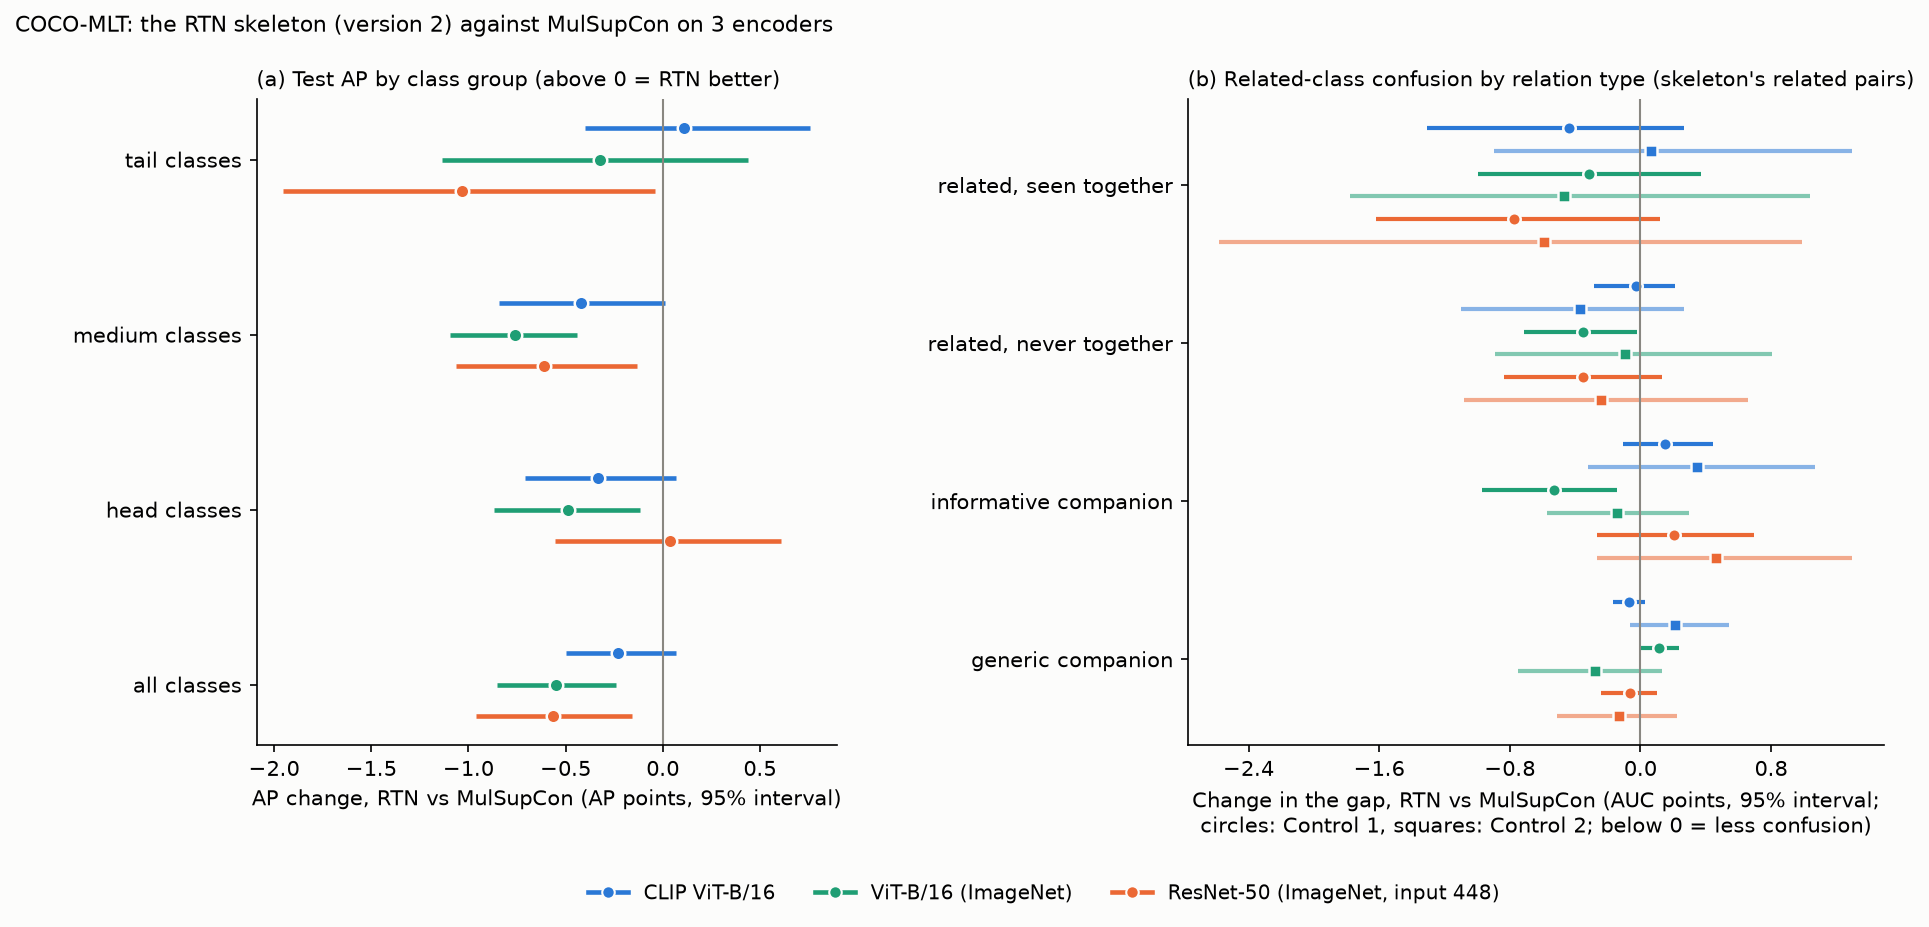

Every skeleton version so far, each against the same MulSupCon runs:
  version 1: relation-typed weights w = 1 + R on MulSupCon's negatives (round 8)
  version 2: component 3: R of a negative only over the labels the anchor does not have


,version,encoder,tail AP change,higher tail mAP (seeds),head AP change,all AP change,"gap change, C1","gap change, C2",verdict
0,1,CLIP ViT-B/16,"+0.44 [-0.33, +1.17]",2/3,"-0.38 [-0.90, +0.18]","-0.15 [-0.49, +0.18]","-0.30 [-0.78, +0.05]","-0.04 [-0.52, +0.49]",NOT SHOWN
1,1,ViT-B/16 (ImageNet),"-0.03 [-0.95, +0.75]",1/3,"-0.85 [-1.37, -0.31]","-0.43 [-0.80, -0.08]","-0.27 [-0.60, +0.04]","-0.58 [-1.21, +0.01]",NOT SHOWN
2,1,"ResNet-50 (ImageNet, input 448)","-0.30 [-1.39, +0.77]",2/3,"+0.06 [-0.44, +0.55]","-0.27 [-0.69, +0.16]","-0.31 [-0.81, +0.14]","-0.32 [-1.62, +0.89]",NOT SHOWN
3,2,CLIP ViT-B/16,"+0.11 [-0.40, +0.76]",1/3,"-0.33 [-0.71, +0.07]","-0.23 [-0.50, +0.07]","-0.16 [-0.49, +0.10]","-0.17 [-0.67, +0.34]",NOT SHOWN
4,2,ViT-B/16 (ImageNet),"-0.32 [-1.13, +0.44]",1/3,"-0.49 [-0.87, -0.11]","-0.55 [-0.86, -0.24]","-0.28 [-0.61, -0.01]","-0.40 [-1.24, +0.55]",NOT SHOWN
5,2,"ResNet-50 (ImageNet, input 448)","-1.03 [-1.95, -0.04]",0/3,"+0.04 [-0.55, +0.61]","-0.57 [-0.96, -0.16]","-0.34 [-0.78, +0.07]","-0.48 [-1.34, +0.32]",NOT SHOWN


Saved the table, figure and summary.txt to c:\Users\Admin\Documents\MSc-Project---RTN\coco_mlt\rtn_skeleton\summary\v2


In [1]:
import importlib
import os
import sys

# This notebook can sit in the project folder or in a folder inside it. The
# project folder is the one with coco_mlt/ and the round 6 files; every path
# below is relative to it.
HERE = os.path.abspath("")
PROJECT = next((p for p in (HERE, os.path.dirname(HERE))
                if os.path.isdir(os.path.join(p, "coco_mlt"))
                and os.path.exists(os.path.join(p, "relation_contrastive_runs.py"))), None)
if PROJECT is None:
    raise SystemExit("Put this notebook in the project folder (the one with coco_mlt/ and "
                     "relation_contrastive_runs.py) or in a folder inside it.")
copies = {os.path.join(p, "rtn_skeleton.py") for p in (HERE, PROJECT)
          if os.path.exists(os.path.join(p, "rtn_skeleton.py"))}
if not copies:
    raise SystemExit("rtn_skeleton.py not found next to this notebook or in the project folder.")
if len(copies) > 1 and len({open(c, "rb").read() for c in copies}) > 1:
    raise SystemExit("There are two different copies of rtn_skeleton.py; keep only one.")
for p in (HERE, PROJECT):
    if p not in sys.path:
        sys.path.insert(0, p)
os.chdir(PROJECT)

import rtn_skeleton as sk
importlib.reload(sk)
print(f"Project folder: {PROJECT}\nSkeleton: {sk.__file__} (version {sk.SKELETON_VERSION})")

sk.summarize("coco_mlt", ["clip", "vit_b16", "resnet50"])

## How to read the results

- One row per encoder, the same skeleton throughout. ViT-B/16 (ImageNet)
  against CLIP ViT-B/16 isolates CLIP's image-text training (same
  architecture and input); ResNet-50 adds a different architecture.
- For context, with the earlier relation types (from CLIP's class-name
  text) RTN raised tail AP by +0.42 on CLIP and +0.82 on ResNet-50, higher
  in 3 of 3 seeds both times.